# 06 | Supporting evidence: exploring the real incident data

Before building Scout's retrieval, I needed to know **what I could honestly learn** from the public records.

Each row is a published vendor incident, **not** an internal root-cause investigation or a verified fix. I checked the number of usable records, missing fields, title lengths, vendor coverage, dates and impact labels.

I used the same loading and cleaning functions as the app. This notebook saves **five actual charts** and a small aggregate report for the presentation.

**Source:** [SevAnalysis](https://sevanalysis.com/data/), CC BY-NC 4.0. Raw records and local case history are not committed.

## 1. Identify the exact downloaded file

I record its size, SHA-256 fingerprint, modification time and shape. The fingerprint identifies the **exact file bytes**; it does **not** establish that the source data is accurate. The dated folder name is not proof of the download date.

In the next cell, `Path` locates the file and `hashlib` calculates its fingerprint without loading another full copy into memory.

In [4]:
# These imports are Python tools, not extra data sources:
# Path = find files; hashlib = calculate a file fingerprint; json = save a summary.
# pandas (pd) = work with rows and columns; matplotlib (plt) = make charts.
# sys lets the notebook find Scout's existing src/ code from either folder.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.incident_assistant import (
    LOCAL_CSV, clean_text, load_incidents, prepare_incidents, safe_http_url
)

csv_path = Path(LOCAL_CSV)
if not csv_path.is_file():
    raise FileNotFoundError(
        "The local SevAnalysis incidents.csv is missing. Save the original "
        "CSV at data/raw/incident_taxonomy/snapshot_2026-10-23/incidents.csv "
        "and rerun this notebook. Do not replace it with synthetic rows."
    )

REPORT_DIR = Path(os.environ.get("SCOUT_EDA_REPORT_DIR", str(ROOT / "reports")))
REPORT_DIR.mkdir(parents=True, exist_ok=True)

raw = load_incidents(csv_path)
clean = prepare_incidents(raw)

sha256 = hashlib.sha256()
with csv_path.open("rb") as file:
    while True:
        chunk = file.read(1024 * 1024)
        if not chunk:
            break
        sha256.update(chunk)

fingerprint = sha256.hexdigest()
modified_utc = datetime.fromtimestamp(
    csv_path.stat().st_mtime, timezone.utc
).isoformat(timespec="seconds")

print("Publisher: SevAnalysis · public vendor status incidents · CC BY-NC 4.0")
print("Filename:", csv_path.name)
print("Snapshot directory:", csv_path.parent.name)
print("File size (MB):", round(csv_path.stat().st_size / (1024 * 1024), 2))
print("File SHA-256:", fingerprint)
print("File modified (UTC, not verified download date):", modified_utc)
print("Raw shape:", raw.shape)
print("Prepared shape:", clean.shape)
print("Raw columns:", ", ".join(raw.columns))


Publisher: SevAnalysis · public vendor status incidents · CC BY-NC 4.0
Filename: incidents.csv
Snapshot directory: snapshot_2026-10-23
File size (MB): 8.91
File SHA-256: b8cb7c89b85db1380ea690a651a12be8437f73c4be19bf4116761c769cf24378
File modified (UTC, not verified download date): 2026-11-09T07:47:05+00:00
Raw shape: (41314, 21)
Prepared shape: (41171, 11)
Raw columns: vendor, vendor_name, tier, id, title, status, impact, started_at, resolved_at, duration_minutes, mitigation_minutes, repeat, components, mentions_upstream, failure_mode, root_cause, customer_detected, stated_recurrence, failover_unused, recovery_unstated, url


## 2. Check what cleaning removed

I compare raw and prepared rows, counting **missing core fields** separately from **duplicates**. Two incidents with similar wording are not automatically duplicates.

An `assert` at the end checks that the totals add up. I do not fill missing incident titles with invented information.

In [5]:
# Step-by-step: compare raw rows with the same prepared records Scout searches.
# .map(clean_text) applies our existing text-cleaning function to each item.
# .ne("") means "not equal to blank", and & means BOTH conditions are true.
# A True value counts as 1 when .sum() is used.

# Use the same text normalisation as Scout's preparation function.
raw_title = raw["title"].map(clean_text)

if "vendor_name" in raw.columns:
    primary_vendor = raw["vendor_name"].map(clean_text)
else:
    primary_vendor = pd.Series("", index=raw.index, dtype="object")

if "vendor" in raw.columns:
    fallback_vendor = raw["vendor"].map(clean_text)
else:
    fallback_vendor = pd.Series("", index=raw.index, dtype="object")

vendor_for_search = primary_vendor.where(primary_vendor.ne(""), fallback_vendor)
eligible = raw_title.ne("") & vendor_for_search.ne("")

raw_count = int(len(raw))
usable_before_dedup = int(eligible.sum())
removed_missing_core = raw_count - usable_before_dedup
prepared_count = int(len(clean))
removed_duplicates = usable_before_dedup - prepared_count

assert removed_duplicates >= 0
assert raw_count == removed_missing_core + removed_duplicates + prepared_count

cleaning = pd.DataFrame([
    {"stage": "Original CSV rows", "rows": raw_count},
    {"stage": "Missing title or vendor", "rows": removed_missing_core},
    {"stage": "Duplicate usable records", "rows": removed_duplicates},
    {"stage": "Prepared searchable records", "rows": prepared_count},
])
display(cleaning)
print("Records retained: {:.1%}".format(prepared_count / raw_count))
print("Unique vendors in prepared records:", clean["vendor"].nunique())
print("Distinct titles in prepared records:", clean["title"].nunique())


,stage,rows
0,Original CSV rows,41314
1,Missing title or vendor,0
2,Duplicate usable records,143
3,Prepared searchable records,41171


Records retained: 99.7%
Unique vendors in prepared records: 364
Distinct titles in prepared records: 30286


## 3. Find the genuinely missing fields

A blank field means **unknown**, not zero. I check empty strings as well as pandas missing values, and verify whether source URLs have a valid format.

I measure missingness **after cleaning**, while reporting dropped core rows separately. Other model-generated labels in the source are **not confirmed causes**.

The code uses `fillna` for counting blanks, `str.strip()` for whitespace and `sum()` to count them.

,field,missing,present,missing_pct
6,Affected components,30031,11140,72.9%
3,Resolution time,86,41085,0.2%
1,Incident title,0,41171,0.0%
0,Vendor,0,41171,0.0%
2,Start time,0,41171,0.0%
4,Impact label,0,41171,0.0%
5,Status,0,41171,0.0%
7,Original source URL,0,41171,0.0%



Optional labels in the source (presence is not verification):
  root_cause: 32,368/41,314 missing or blank
  failure_mode: 32,368/41,314 missing or blank


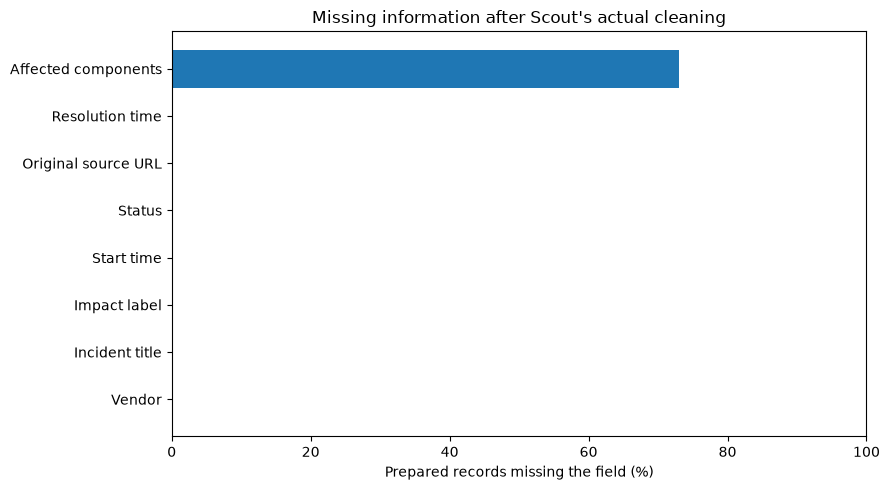

In [6]:
# For every important field, count missing or blank values.
# "Missing percentage" = missing records / all prepared records * 100.
# The chart is about data availability, not whether an outage happened.

fields = [
    ("Vendor", "vendor"),
    ("Incident title", "title"),
    ("Start time", "started_at"),
    ("Resolution time", "resolved_at"),
    ("Impact label", "impact"),
    ("Status", "status"),
    ("Affected components", "components"),
    ("Original source URL", "source_url"),
]

missing_rows = []
for label, column in fields:
    missing_count = int(clean[column].fillna("").astype(str).str.strip().eq("").sum())
    missing_rows.append({
        "field": label, "missing": missing_count,
        "present": prepared_count - missing_count,
        "missing_pct": 100 * missing_count / prepared_count,
    })
missing_df = pd.DataFrame(missing_rows).sort_values(
    "missing_pct", ascending=False
)
display(missing_df.style.format({"missing_pct": "{:.1f}%"}))

model_label_columns = [
    column for column in ["root_cause", "failure_mode"]
    if column in raw.columns
]
if model_label_columns:
    print("\nOptional labels in the source (presence is not verification):")
    for column in model_label_columns:
        missing_count = int(raw[column].map(clean_text).eq("").sum())
        print(f"  {column}: {missing_count:,}/{raw_count:,} missing or blank")
else:
    print("\nNo root_cause/failure_mode columns found in this snapshot.")

fig, ax = plt.subplots(figsize=(9, 5))
ascending = missing_df.sort_values("missing_pct")
ax.barh(ascending["field"], ascending["missing_pct"])
ax.set_xlim(0, 100)
ax.set_xlabel("Prepared records missing the field (%)")
ax.set_title("Missing information after Scout's actual cleaning")
plt.tight_layout()
fig.savefig(REPORT_DIR / "source_eda_missingness.png", dpi=170, bbox_inches="tight")
plt.show()


## 4. How informative are the titles?

I count the words per title and show the median and 10th/90th percentiles. This matters because short titles make paraphrased search questions harder to match.

The histogram caps its display at 40 words **for readability only**; all reported summary statistics use the full lengths.

,title_words
count,41171.0
mean,6.4
std,3.5
min,1.0
10%,3.0
50%,6.0
90%,11.0
max,42.0


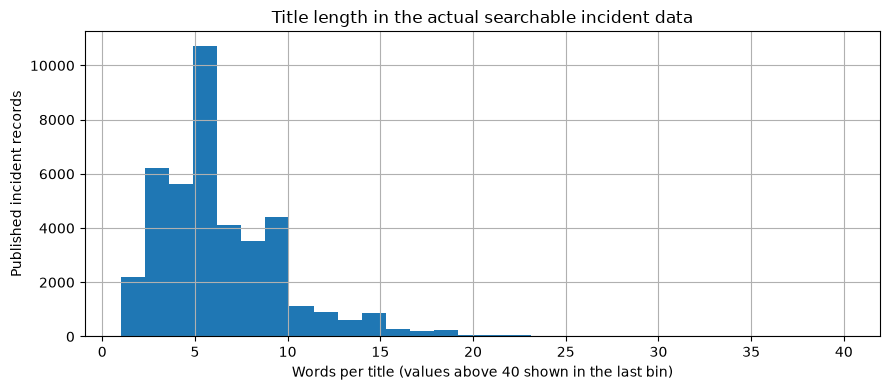

Typical title: median 6 words (10th percentile 3, 90th percentile 11).


In [7]:
# A title becomes a list of words (.str.split); then .str.len counts them.
# The median is the middle length. Quantiles 0.10 and 0.90 show the shorter
# and longer ends of the distribution without focusing on extreme examples.

title_words = clean["title"].fillna("").astype(str).str.split().str.len()
title_summary = title_words.describe(percentiles=[0.10, 0.50, 0.90])
display(title_summary.to_frame(name="title_words").round(1))

fig, ax = plt.subplots(figsize=(9, 4))
title_words.clip(upper=40).hist(ax=ax, bins=30)
ax.set_xlabel("Words per title (values above 40 shown in the last bin)")
ax.set_ylabel("Published incident records")
ax.set_title("Title length in the actual searchable incident data")
plt.tight_layout()
fig.savefig(REPORT_DIR / "source_eda_title_lengths.png", dpi=170, bbox_inches="tight")
plt.show()

print(
    "Typical title: median {:g} words (10th percentile {:g}, 90th percentile {:g})."
    .format(title_words.median(), title_words.quantile(0.10),
            title_words.quantile(0.90))
)


## 5. Is coverage even across vendors?

I count reports per vendor with `value_counts()` and chart the 12 largest groups. More published records do **not** prove a service is less reliable. Reporting habits and dataset coverage may differ.

This helps explain why a retriever can rank a similar-sounding report from the **wrong supplier**.

,vendor,published_incidents
0,Twilio,4133
1,Jina AI,2745
2,Hostinger,1208
3,Scaleway,996
4,Moonshot AI (Kimi),873
5,Kraken,813
6,QuickNode,793
7,Anthropic (Claude),752
8,Flutterwave,740
9,Bandwidth,661


Share of records from 12 most represented vendors: 36.2%


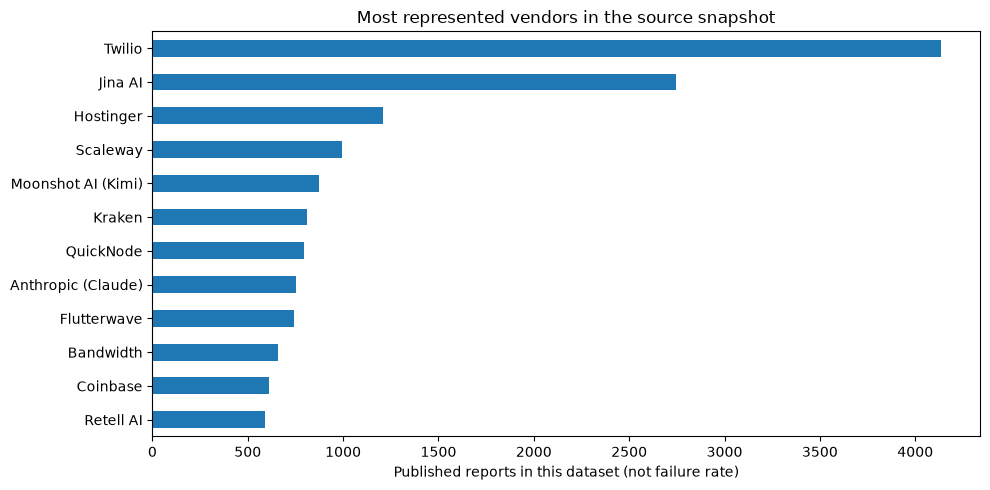

In [8]:
# value_counts() groups rows by supplier and counts them.
# head(12) selects only the 12 largest for a legible figure.
# This measures data coverage, NOT the frequency of real-world failures.

vendor_counts = clean["vendor"].value_counts()
top_vendors = vendor_counts.head(12)
share_top_12 = top_vendors.sum() / prepared_count
display(
    top_vendors.rename_axis("vendor").reset_index(name="published_incidents")
)
print("Share of records from 12 most represented vendors: {:.1%}".format(
    share_top_12
))

fig, ax = plt.subplots(figsize=(10, 5))
top_vendors.iloc[::-1].plot(kind="barh", ax=ax)
ax.set_xlabel("Published reports in this dataset (not failure rate)")
ax.set_ylabel("")
ax.set_title("Most represented vendors in the source snapshot")
plt.tight_layout()
fig.savefig(REPORT_DIR / "source_eda_vendor_coverage.png", dpi=170, bbox_inches="tight")
plt.show()


## 6. What time period does this file cover?

I convert reported start times to UTC and check for invalid dates. A monthly chart shows recent **record coverage**, not the true rate of outages.

The code groups dates by month and includes zero-count months inside the observed range. First and last months may be incomplete.

Valid UTC start timestamps: 41,171/41,171
Missing or unparseable start timestamps: 0
Earliest reported start: 2015-11-30T12:00:00+00:00
Latest reported start: 2026-11-08T19:30:00+00:00


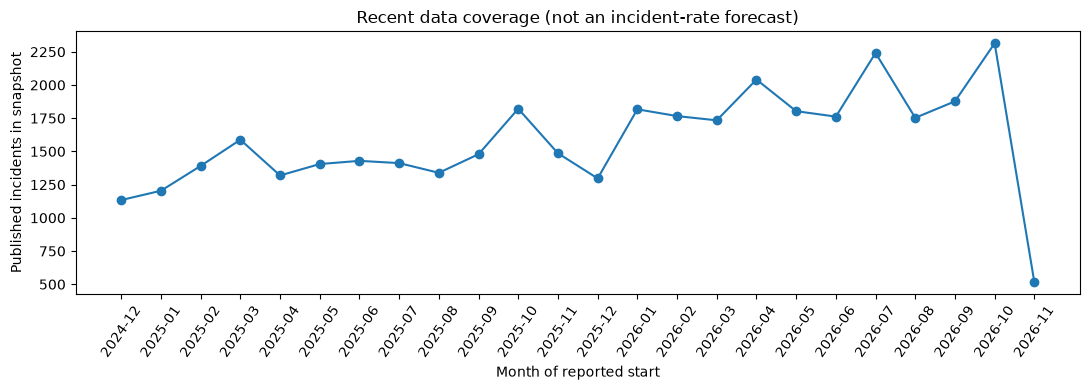

In [9]:
# Turn text timestamps into dates, keeping a common UTC timezone.
# Invalid dates become missing (errors="coerce") rather than guessed dates.
# Then count records per calendar month. A chart of data coverage is NOT
# evidence that reliability improved or worsened over time.

parsed_starts = pd.to_datetime(
    clean["started_at"].replace("", pd.NA), errors="coerce", utc=True
)
date_valid = int(parsed_starts.notna().sum())
date_missing_or_invalid = prepared_count - date_valid
print("Valid UTC start timestamps:", f"{date_valid:,}/{prepared_count:,}")
print("Missing or unparseable start timestamps:", date_missing_or_invalid)

monthly_tail = pd.Series(dtype="int64")
first_recorded_month = None
last_recorded_month = None

if date_valid:
    valid_starts = parsed_starts.dropna()
    first_recorded_month = valid_starts.min().isoformat()
    last_recorded_month = valid_starts.max().isoformat()
    print("Earliest reported start:", first_recorded_month)
    print("Latest reported start:", last_recorded_month)

    monthly = (
        valid_starts.dt.tz_localize(None).dt.to_period("M")
        .value_counts().sort_index()
    )
    # Reindex to include zero months in the displayed range, if any.
    monthly = monthly.reindex(
        pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"),
        fill_value=0
    )
    monthly_tail = monthly.tail(24)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(monthly_tail.index.astype(str), monthly_tail.to_numpy(), marker="o")
    ax.set_ylabel("Published incidents in snapshot")
    ax.set_xlabel("Month of reported start")
    ax.set_title("Recent data coverage (not an incident-rate forecast)")
    ax.tick_params(axis="x", rotation=55)
    plt.tight_layout()
    fig.savefig(REPORT_DIR / "source_eda_monthly_coverage.png", dpi=170,
                bbox_inches="tight")
    plt.show()
else:
    print("No valid start timestamps: cannot draw the monthly coverage chart.")


## 7. What do the impact labels mean?

I count the **vendor-published** impact labels. Blank ones become **Unknown**, not "no impact".

I use a bar chart for categories, but I cannot treat "major" or "critical" as a common measurement across every supplier.

,impact,records
0,minor,21844
1,major,7890
2,none,7543
3,critical,3497
4,unknown,397


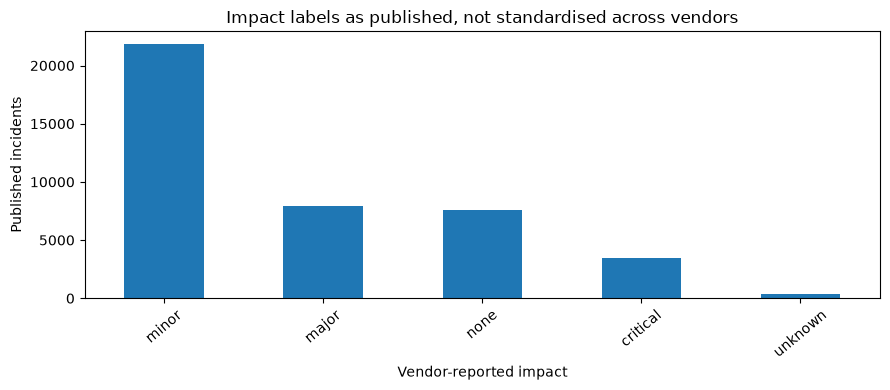

In [10]:
# Replace blank impact labels with "Unknown", not zero or "no impact".
# Count each recorded category. Group uncommon labels on the chart only,
# because these vendor labels are not a standard severity score.

impact_labels = clean["impact"].fillna("").astype(str).str.strip()
impact_labels = impact_labels.mask(impact_labels.eq(""), "Unknown")
impact_counts = impact_labels.value_counts()
display(impact_counts.rename_axis("impact").reset_index(name="records").head(15))

display_counts = impact_counts.head(10).copy()
if len(impact_counts) > 10:
    display_counts.loc["Other recorded labels"] = int(impact_counts.iloc[10:].sum())

fig, ax = plt.subplots(figsize=(9, 4))
display_counts.plot(kind="bar", ax=ax)
ax.set_ylabel("Published incidents")
ax.set_xlabel("Vendor-reported impact")
ax.set_title("Impact labels as published, not standardised across vendors")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
fig.savefig(REPORT_DIR / "source_eda_impact_labels.png", dpi=170,
            bbox_inches="tight")
plt.show()


## 8. Preserve the evidence

I save a JSON file of **aggregate measures**, the CSV fingerprint and the five charts under `reports/`. No raw incident text or personal case history goes into those exports.

The test suite runs this code against a tiny synthetic CSV in a **separate folder**; that test does not produce the real project findings.

In [11]:
# Collect the real calculations into a dictionary (named values).
# Write the totals as JSON for reproducibility alongside the PNG charts.
# This does not publish the original incident descriptions or case messages.

metrics = {
    "source": "SevAnalysis public vendor status-page reports",
    "licence": "CC BY-NC 4.0",
    "filename": csv_path.name,
    "snapshot_label": csv_path.parent.name,
    "file_modified_utc_not_verified_download_date": modified_utc,
    "sha256": fingerprint,
    "raw_rows": raw_count,
    "raw_columns": int(raw.shape[1]),
    "usable_before_deduplication": usable_before_dedup,
    "rows_missing_core_fields": removed_missing_core,
    "duplicate_usable_rows": removed_duplicates,
    "prepared_rows": prepared_count,
    "retention_pct": round(100 * prepared_count / raw_count, 2),
    "unique_vendors": int(clean["vendor"].nunique()),
    "distinct_titles": int(clean["title"].nunique()),
    "missing_pct_prepared": {
        row["field"]: round(float(row["missing_pct"]), 2)
        for row in missing_rows
    },
    "title_length_words": {
        "p10": float(title_words.quantile(0.10)),
        "median": float(title_words.median()),
        "p90": float(title_words.quantile(0.90)),
    },
    "top_12_vendor_record_share_pct": round(100 * share_top_12, 2),
    "valid_start_timestamps": date_valid,
    "missing_or_invalid_start_timestamps": date_missing_or_invalid,
    "earliest_reported_start": first_recorded_month,
    "latest_reported_start": last_recorded_month,
    "impact_label_counts": {
        str(label): int(count) for label, count in impact_counts.items()
    },
}

summary_path = REPORT_DIR / "source_eda_metrics.json"
summary_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

print("Evidence files written to:", REPORT_DIR.name)
for file in sorted(REPORT_DIR.glob("source_eda_*")):
    print(" -", file.name)

assert summary_path.is_file()
assert prepared_count + removed_duplicates + removed_missing_core == raw_count


Evidence files written to: reports
 - source_eda_impact_labels.png
 - source_eda_metrics.json
 - source_eda_missingness.png
 - source_eda_monthly_coverage.png
 - source_eda_title_lengths.png
 - source_eda_vendor_coverage.png


## 9. How the EDA affected the design

- **Cleaning:** show exactly how many records were removed and why.
- **Missing components:** search the available text instead of depending on complete technical categories.
- **Short titles:** expect wording differences and measure retrieval rather than assume a match.
- **Vendor concentration:** keep supplier names visible and inspect wrong-vendor matches.
- **Dates and impact:** useful context, but not confirmed causes, severity rankings or continuous monitoring.

This led me to compare keyword overlap with TF-IDF and then test **answer accuracy separately**. The charts describe the source; they do not prove Scout's diagnosis accuracy.

## 10. Results from my actual downloaded CSV

These are the saved real-data measurements, not figures from the synthetic test:

| Check | Measured result |
|---|---:|
| Raw rows and columns | **41,314 rows · 21 columns** |
| Searchable incidents | **41,171** (99.65% retained) |
| Duplicate rows removed | **143** |
| Rows dropped for missing title/vendor | **0** |
| Vendors | **364** |
| Missing affected-component field | **72.94%** |
| Missing resolution time | **0.21%** |
| Median title length | **6 words** (10th percentile 3; 90th percentile 11) |
| Top 12 vendors' share | **36.23%** |
| Valid start timestamps | **41,171** |

The saved file fingerprint starts `b8cb7c89` and is recorded in [the metrics file](../reports/source_eda_metrics.json). This identifies the analysed version, not the publisher's release date.

**My conclusion:** there is enough public history to retrieve possible parallels, but too little verified detail to infer a current root cause. That is why Scout separates **source links**, **checked procedures** and **unverified AI explanations**.

The five charts are saved alongside the metrics in `reports/` and embedded in the executed cells above.